In [20]:
!pip install catboost

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split, cross_val_score, KFold, LeaveOneOut, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error

# Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, BayesianRidge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

# Neural Network
from tensorflow import keras
from tensorflow.keras import layers, callbacks

# Statistical tools
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from scipy.stats import boxcox

In [2]:
df = pd.read_csv('dataset final_Ver1 (1).csv')
df.head()

,الربع,السنه المالية,وحدة القياس,الناتج المحلي الاجمالي بسعر السوق (بالمليار جنيه),الواردات (بالمليار جنيه),الإيرادات الفعليه (بالمليار جنيه),معدل التضخم الاساسى,عدد المسجلين
0,الربع الرابع,2025/2024,مليار جنيه,4582,1342,249.348,3.10%,945648
1,الربع الثالث,2025/2024,مليار جنيه,4558,1315,239.813,4.55%,930891
2,الربع الثاني,2025/2024,مليار جنيه,4570,1380,233.898,1.83%,916533
3,الربع الأول,2025/2024,مليار جنيه,4619,1332,189.721,4.53%,901829
4,الربع الرابع,2024/2023,مليار جنيه,3528,1104,196.267,1.95%,888004


In [3]:
df = df.rename(columns={
    'الربع': 'Quarter',
    'السنه المالية': 'Fiscal_Year',
    'وحدة القياس': 'Unit_of_Measurement',
    'الناتج المحلي الاجمالي بسعر السوق (بالمليار جنيه)': 'GDP_Market_Price',
    'الواردات (بالمليار جنيه)': 'Imports',
    'الإيرادات الفعليه (بالمليار جنيه)': 'Actual_Revenue',
    'معدل التضخم الاساسى': 'Inflation_Rate',
    'عدد المسجلين': 'Number_Registered'
})

In [4]:
df.head()

,Quarter,Fiscal_Year,Unit_of_Measurement,GDP_Market_Price,Imports,Actual_Revenue,Inflation_Rate,Number_Registered
0,الربع الرابع,2025/2024,مليار جنيه,4582,1342,249.348,3.10%,945648
1,الربع الثالث,2025/2024,مليار جنيه,4558,1315,239.813,4.55%,930891
2,الربع الثاني,2025/2024,مليار جنيه,4570,1380,233.898,1.83%,916533
3,الربع الأول,2025/2024,مليار جنيه,4619,1332,189.721,4.53%,901829
4,الربع الرابع,2024/2023,مليار جنيه,3528,1104,196.267,1.95%,888004


In [5]:
df = df.drop(columns=['Unit_of_Measurement'])

In [6]:
# Method 1: Using replace() with a dictionary
df['Quarter'] = df['Quarter'].replace({
    'الربع الأول': 1,
    'الربع الثاني': 2,
    'الربع الثالث': 3,
    'الربع الرابع': 4
})

df.head()

,Quarter,Fiscal_Year,GDP_Market_Price,Imports,Actual_Revenue,Inflation_Rate,Number_Registered
0,4,2025/2024,4582,1342,249.348,3.10%,945648
1,3,2025/2024,4558,1315,239.813,4.55%,930891
2,2,2025/2024,4570,1380,233.898,1.83%,916533
3,1,2025/2024,4619,1332,189.721,4.53%,901829
4,4,2024/2023,3528,1104,196.267,1.95%,888004


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Quarter            60 non-null     int64  
 1   Fiscal_Year        60 non-null     object 
 2   GDP_Market_Price   60 non-null     int64  
 3   Imports            60 non-null     int64  
 4   Actual_Revenue     60 non-null     float64
 5   Inflation_Rate     60 non-null     object 
 6   Number_Registered  60 non-null     int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 3.4+ KB


In [8]:
df['Fiscal_Year'] = df['Fiscal_Year'].str.split('/').str[0].astype(int)
df['Inflation_Rate'] = df['Inflation_Rate'].str.replace('%', '').astype(float) / 100
df.head()

,Quarter,Fiscal_Year,GDP_Market_Price,Imports,Actual_Revenue,Inflation_Rate,Number_Registered
0,4,2025,4582,1342,249.348,0.0310,945648
1,3,2025,4558,1315,239.813,0.0455,930891
2,2,2025,4570,1380,233.898,0.0183,916533
3,1,2025,4619,1332,189.721,0.0453,901829
4,4,2024,3528,1104,196.267,0.0195,888004


In [9]:
#df.to_csv('df_tax.csv', index=False)

In [10]:
print(df.isnull().sum())
print(df.duplicated().sum())

Quarter              0
Fiscal_Year          0
GDP_Market_Price     0
Imports              0
Actual_Revenue       0
Inflation_Rate       0
Number_Registered    0
dtype: int64
0


In [11]:
df.dtypes

,0
Quarter,int64
Fiscal_Year,int64
GDP_Market_Price,int64
Imports,int64
Actual_Revenue,float64
Inflation_Rate,float64
Number_Registered,int64


In [12]:
# Sort by Fiscal_Year and Quarter for time series analysis
df = df.sort_values(['Fiscal_Year', 'Quarter']).reset_index(drop=True)
df.head()

,Quarter,Fiscal_Year,GDP_Market_Price,Imports,Actual_Revenue,Inflation_Rate,Number_Registered
0,1,2011,364,87,15.530,0.0705,166025
1,2,2011,341,85,18.148,-0.0012,170004
2,3,2011,316,74,16.510,0.0251,173357
3,4,2011,349,90,23.913,0.0183,176615
4,1,2012,428,99,15.029,0.0373,179743


OUTLIER DETECTION


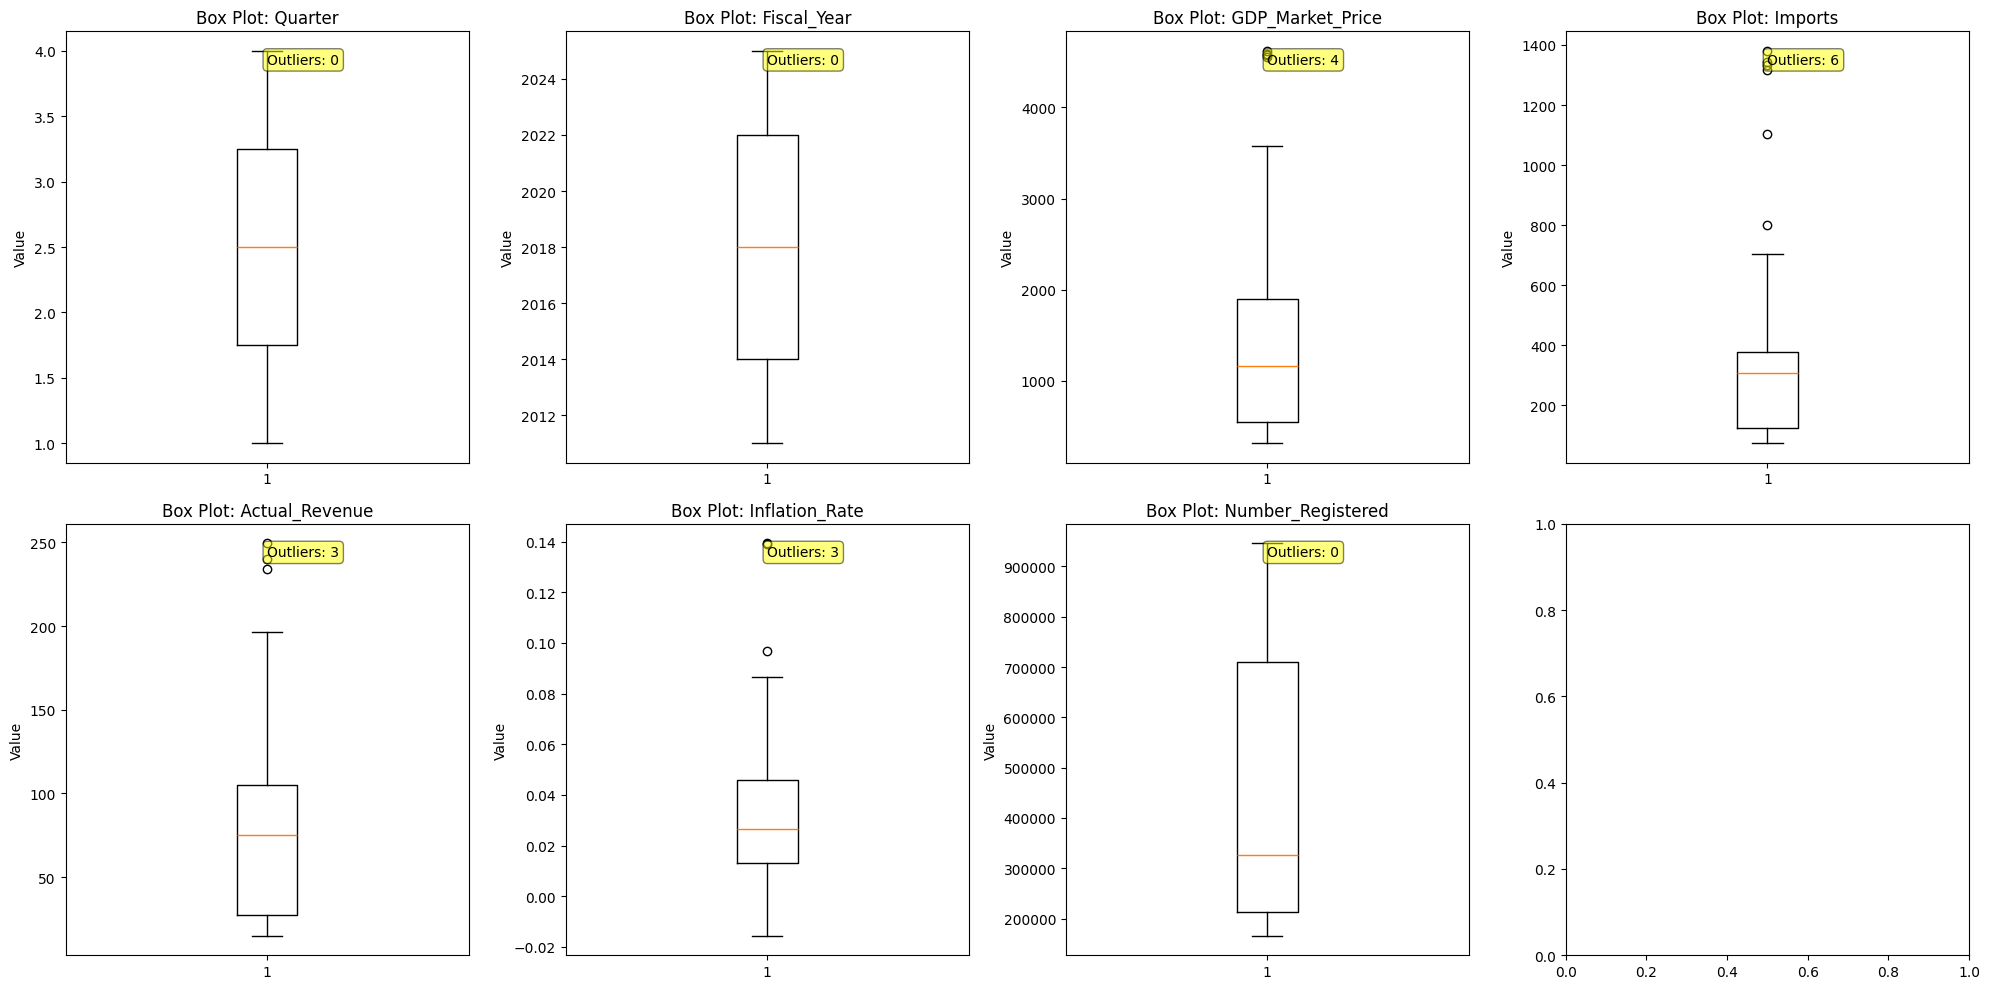

In [13]:
print("OUTLIER DETECTION")
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
for idx, col in enumerate(numeric_cols):
    # Box plot
    axes[idx].boxplot(df[col].dropna())
    axes[idx].set_title(f'Box Plot: {col}')
    axes[idx].set_ylabel('Value')

    # Calculate outliers using IQR
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][col]

    axes[idx].text(0.5, 0.95, f'Outliers: {len(outliers)}',
                   transform=axes[idx].transAxes,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

plt.tight_layout()
plt.show()

In [14]:
import scipy.stats as stats
# Z-score outlier detection
print("\nZ-Score Outlier Analysis (|z| > 3):")
for col in numeric_cols:
    z_scores = np.abs(stats.zscore(df[col]))
    outliers = df[z_scores > 3]
    print(f"{col}: {len(outliers)} outliers")


Z-Score Outlier Analysis (|z| > 3):
Quarter: 0 outliers
Fiscal_Year: 0 outliers
GDP_Market_Price: 0 outliers
Imports: 1 outliers
Actual_Revenue: 0 outliers
Inflation_Rate: 2 outliers
Number_Registered: 0 outliers


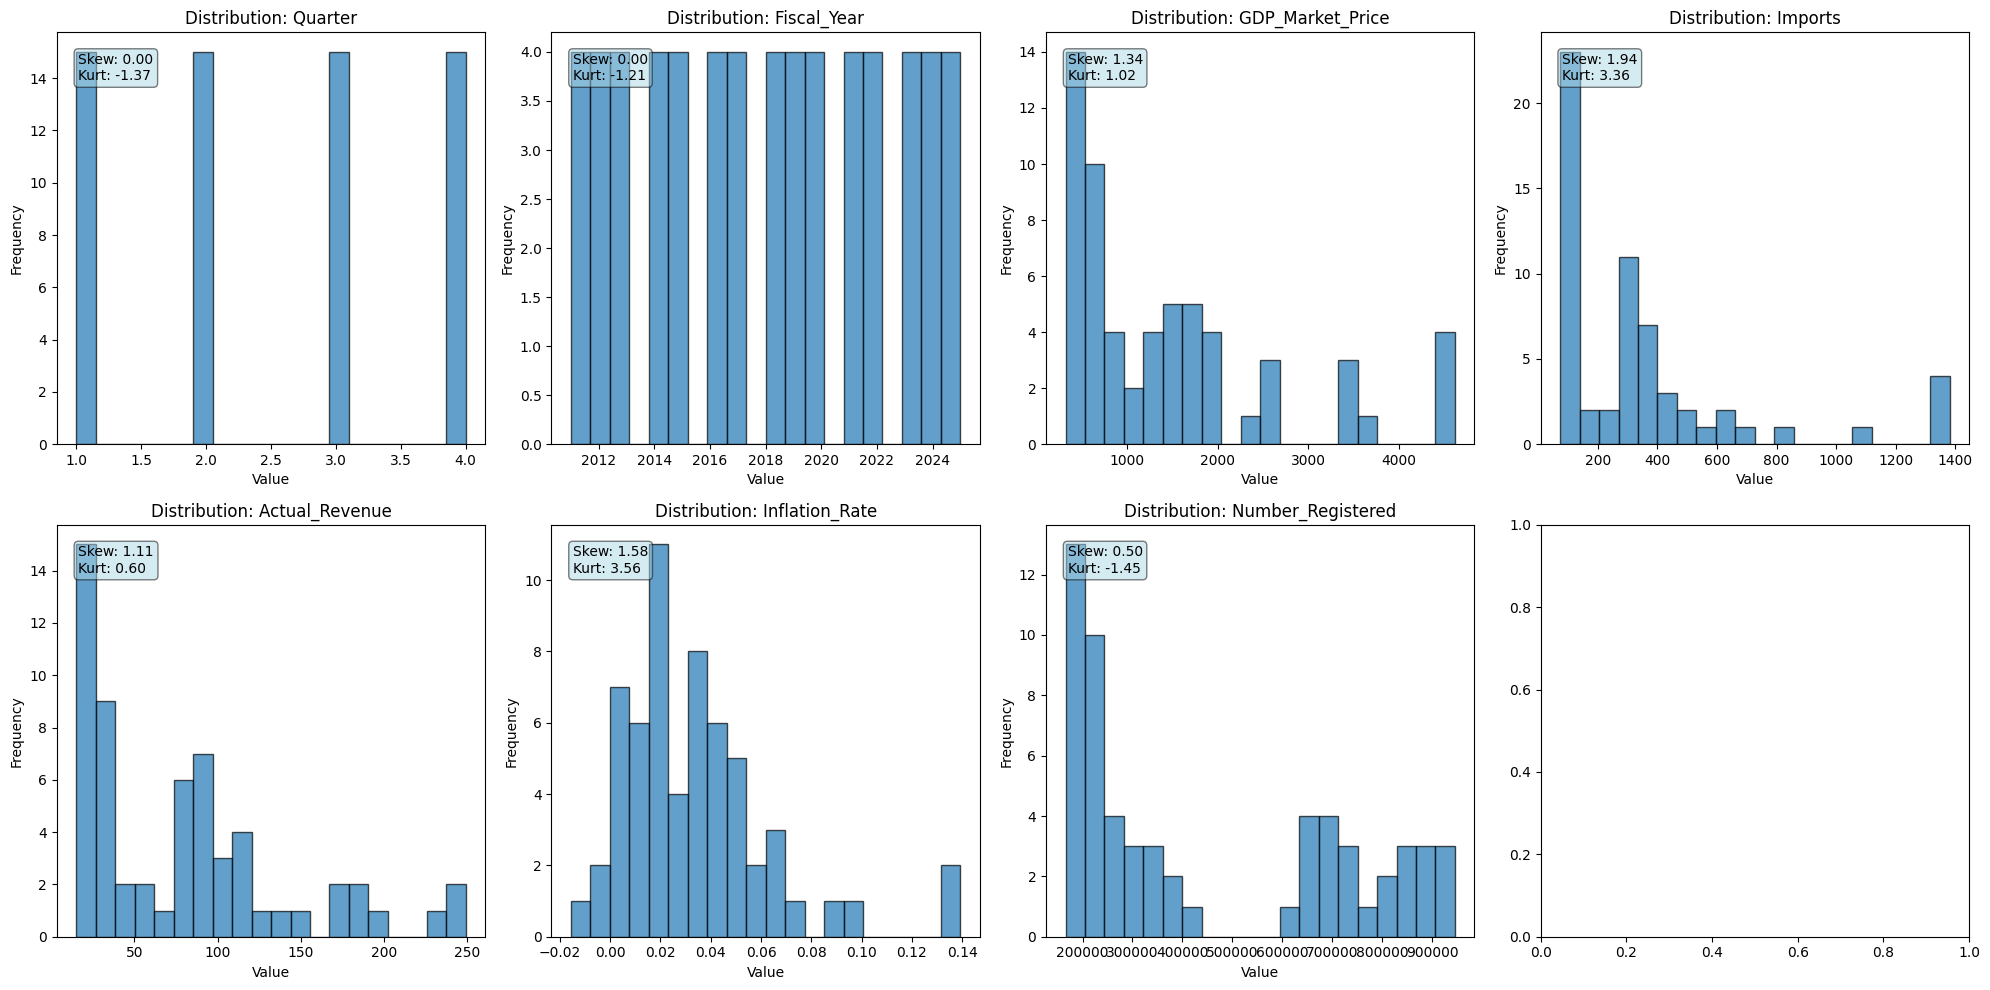

In [15]:
# Distribution Analysis

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    axes[idx].hist(df[col].dropna(), bins=20, edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Distribution: {col}')
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Frequency')

    # Add skewness and kurtosis
    skewness = df[col].skew()
    kurtosis = df[col].kurtosis()
    axes[idx].text(0.05, 0.95, f'Skew: {skewness:.2f}\nKurt: {kurtosis:.2f}',
                   transform=axes[idx].transAxes,
                   verticalalignment='top',
                   bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.5))

plt.tight_layout()
plt.show()

In [16]:
# Normality tests
print("\nShapiro-Wilk Normality Test (p > 0.05 = normal):")
for col in numeric_cols:
    stat, p_value = stats.shapiro(df[col].dropna())
    print(f"{col}: statistic={stat:.4f}, p-value={p_value:.4f} {'(Normal)' if p_value > 0.05 else '(Not Normal)'}")


Shapiro-Wilk Normality Test (p > 0.05 = normal):
Quarter: statistic=0.8562, p-value=0.0000 (Not Normal)
Fiscal_Year: statistic=0.9462, p-value=0.0104 (Not Normal)
GDP_Market_Price: statistic=0.8263, p-value=0.0000 (Not Normal)
Imports: statistic=0.7342, p-value=0.0000 (Not Normal)
Actual_Revenue: statistic=0.8673, p-value=0.0000 (Not Normal)
Inflation_Rate: statistic=0.8792, p-value=0.0000 (Not Normal)
Number_Registered: statistic=0.8309, p-value=0.0000 (Not Normal)


In [17]:
# Statistical summary
df.describe()

,Quarter,Fiscal_Year,GDP_Market_Price,Imports,Actual_Revenue,Inflation_Rate,Number_Registered
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,2.500000,2018.000000,1485.483333,356.200000,79.220683,0.033658,456567.016667
std,1.127469,4.356954,1199.087457,332.857215,61.971784,0.030152,274330.196123
min,1.000000,2011.000000,316.000000,74.000000,15.029000,-0.015600,166025.000000
25%,1.750000,2014.000000,549.250000,123.250000,27.625500,0.013125,213749.500000
50%,2.500000,2018.000000,1166.500000,308.000000,75.189500,0.026350,326313.000000
75%,3.250000,2022.000000,1894.750000,377.750000,105.306000,0.045725,709254.000000
max,4.000000,2025.000000,4619.000000,1380.000000,249.348000,0.139300,945648.000000


In [18]:
# Select only numeric columns for correlation
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Calculate correlation with Actual_Revenue
correlations = df[numeric_cols].corr()['Actual_Revenue'].sort_values(ascending=False)
print(correlations)

Actual_Revenue       1.000000
GDP_Market_Price     0.964017
Imports              0.948013
Number_Registered    0.919305
Fiscal_Year          0.907647
Inflation_Rate       0.227153
Quarter              0.169742
Name: Actual_Revenue, dtype: float64


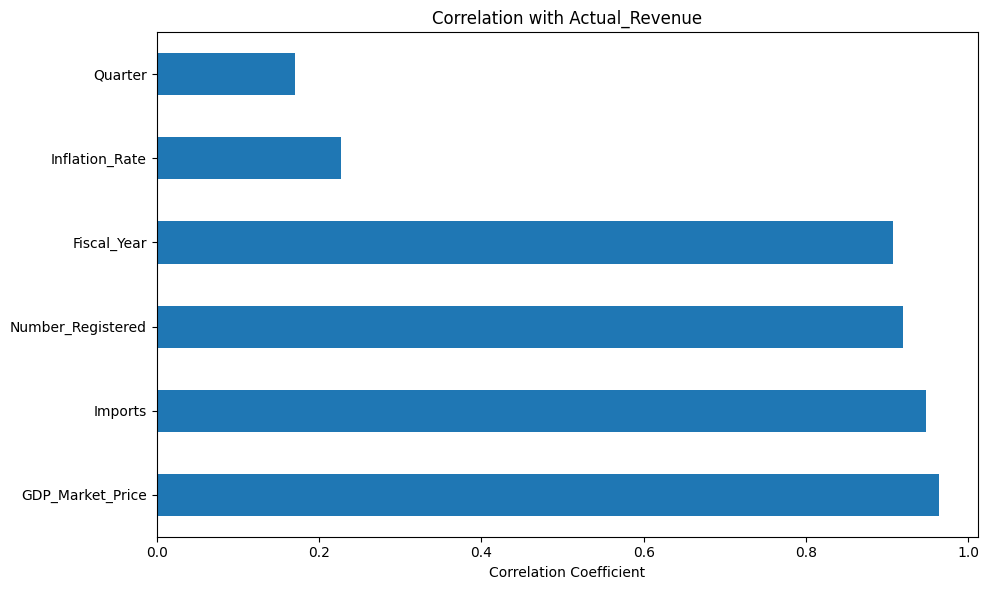

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation bar plot
correlations_filtered = correlations.drop('Actual_Revenue')  # Remove self-correlation
plt.figure(figsize=(10, 6))
correlations_filtered.plot(kind='barh')
plt.title('Correlation with Actual_Revenue')
plt.xlabel('Correlation Coefficient')
plt.tight_layout()
plt.show()

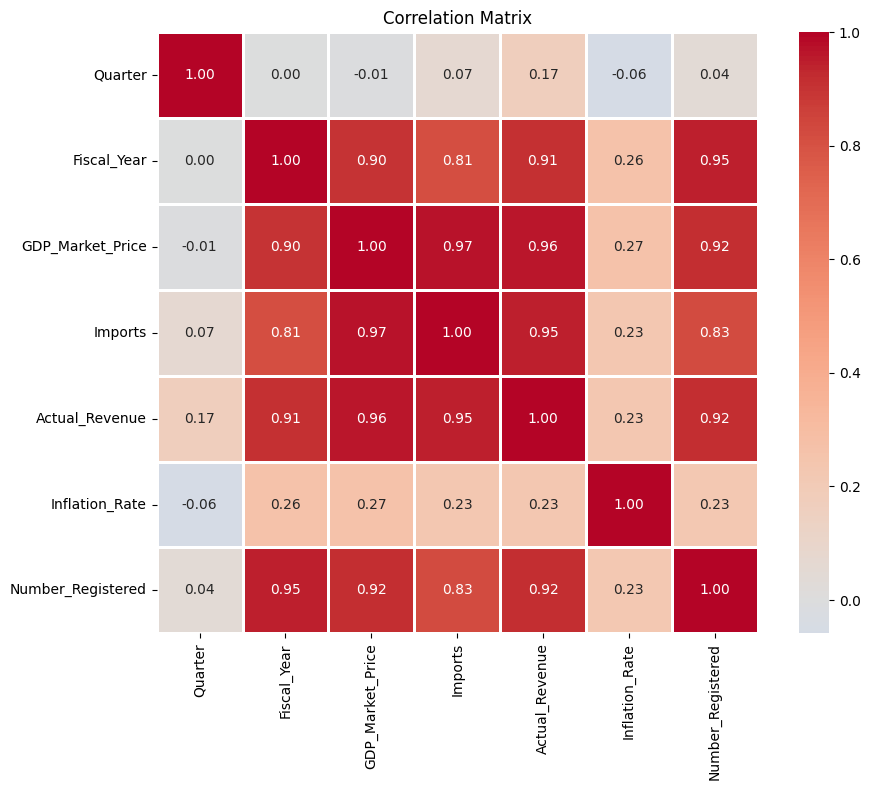

In [20]:
# Heatmap of all correlations
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0,
            fmt='.2f', square=True, linewidths=1)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [21]:
X_for_vif = df[['Fiscal_Year', 'Quarter', 'GDP_Market_Price', 'Imports',
                'Inflation_Rate', 'Number_Registered']]

vif_data = pd.DataFrame()
vif_data["Feature"] = X_for_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_for_vif.values, i)
                   for i in range(X_for_vif.shape[1])]
vif_data = vif_data.sort_values('VIF', ascending=False)

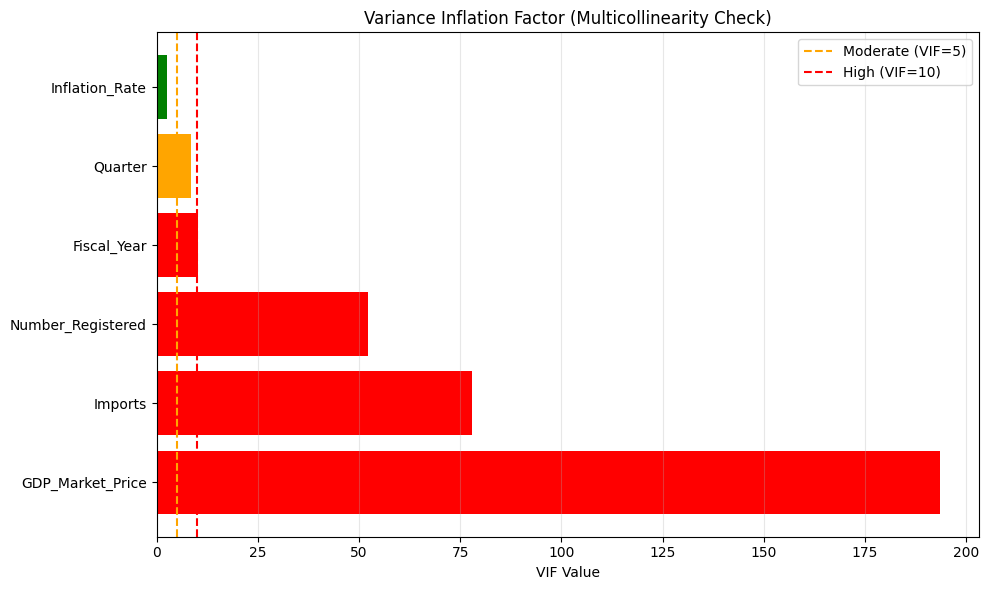

In [22]:
plt.figure(figsize=(10, 6))
colors = ['red' if x > 10 else 'orange' if x > 5 else 'green' for x in vif_data['VIF']]
plt.barh(vif_data['Feature'], vif_data['VIF'], color=colors)
plt.xlabel('VIF Value')
plt.title('Variance Inflation Factor (Multicollinearity Check)')
plt.axvline(x=5, color='orange', linestyle='--', label='Moderate (VIF=5)')
plt.axvline(x=10, color='red', linestyle='--', label='High (VIF=10)')
plt.legend()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

FEATURE-TARGET RELATIONSHIPS


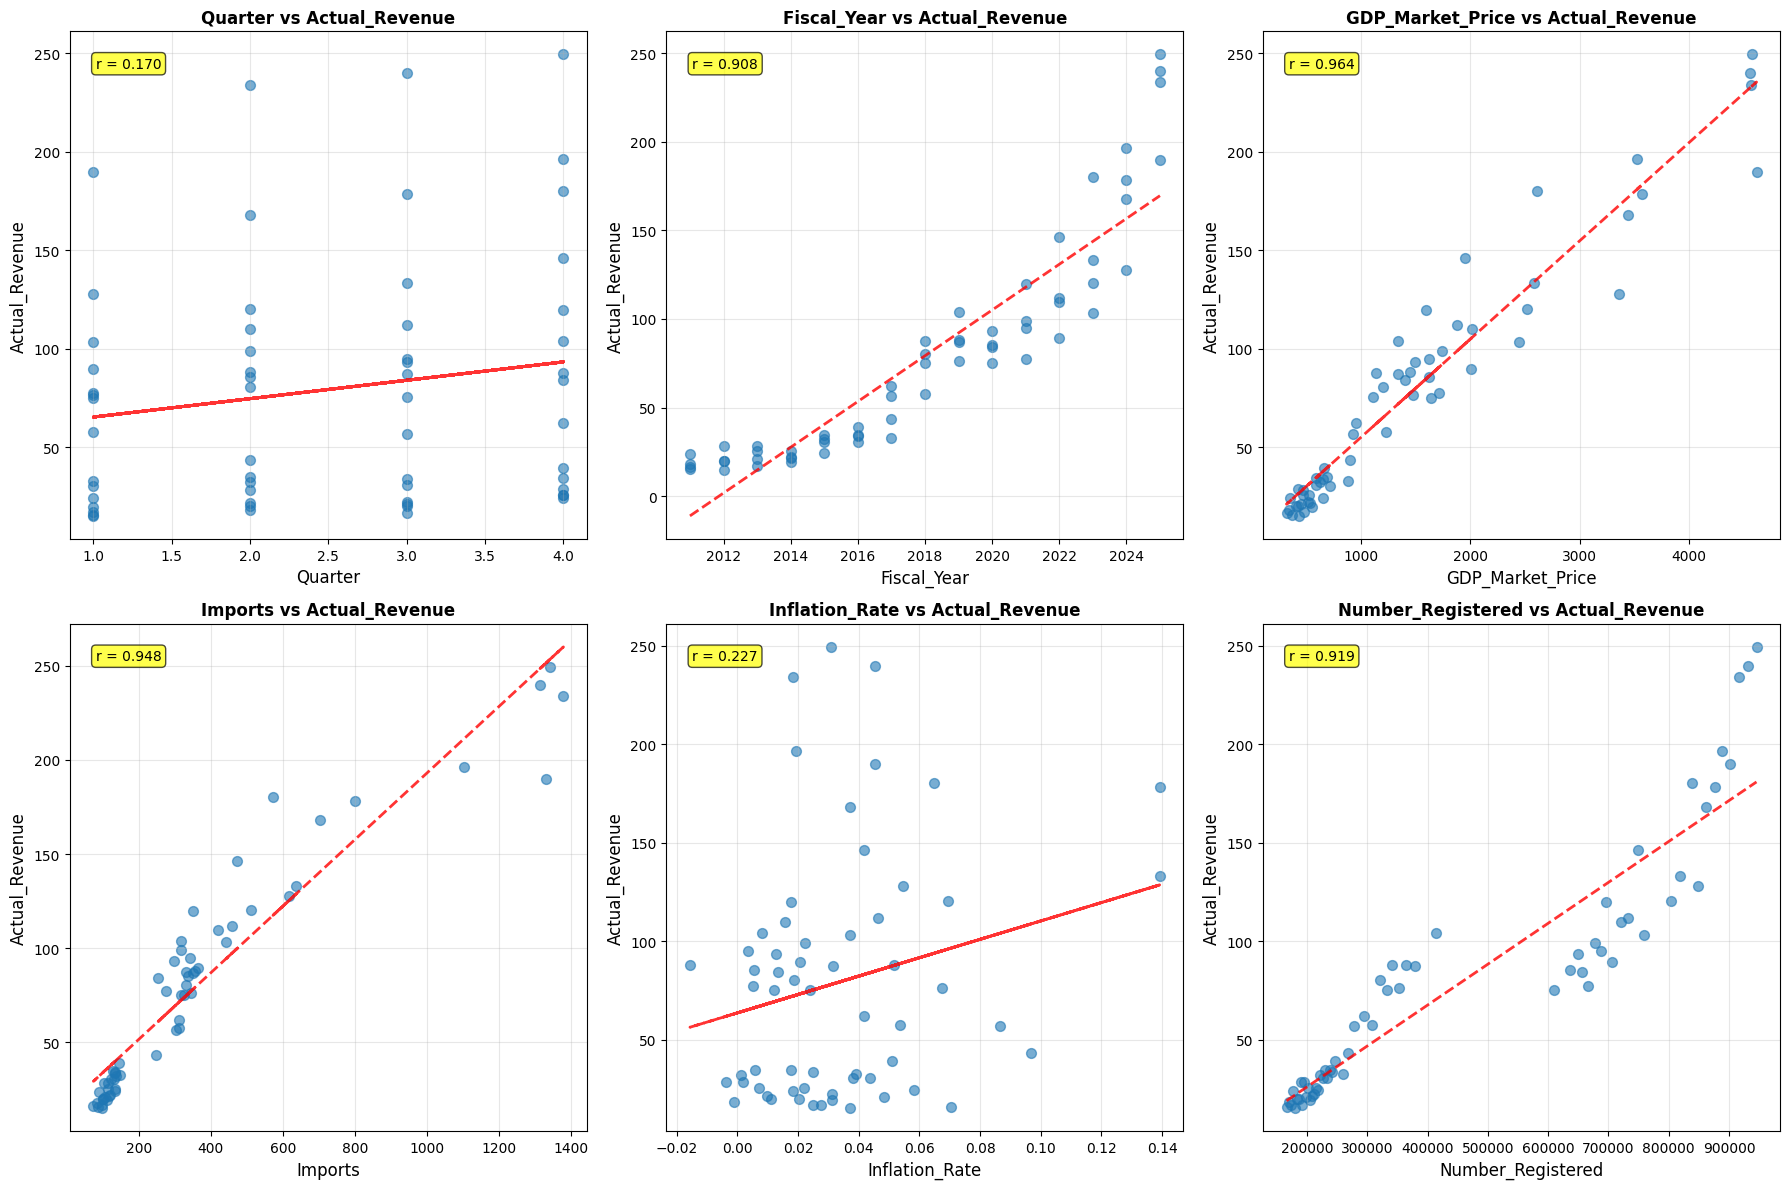

In [23]:
print("FEATURE-TARGET RELATIONSHIPS")

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

features = ['Quarter', 'Fiscal_Year', 'GDP_Market_Price', 'Imports',
            'Inflation_Rate', 'Number_Registered']

for i, feature in enumerate(features):
    axes[i].scatter(df[feature], df['Actual_Revenue'], alpha=0.6, s=50)
    axes[i].set_xlabel(feature, fontsize=12)
    axes[i].set_ylabel('Actual_Revenue', fontsize=12)
    axes[i].set_title(f'{feature} vs Actual_Revenue', fontsize=12, fontweight='bold')

    # Add trend line
    z = np.polyfit(df[feature], df['Actual_Revenue'], 1)
    p = np.poly1d(z)
    axes[i].plot(df[feature], p(df[feature]), "r--", alpha=0.8, linewidth=2)

    # Add correlation
    corr = df[feature].corr(df['Actual_Revenue'])
    axes[i].text(0.05, 0.95, f'r = {corr:.3f}',
                 transform=axes[i].transAxes,
                 verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7),
                 fontsize=10)

    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

TIME SERIES ANALYSIS


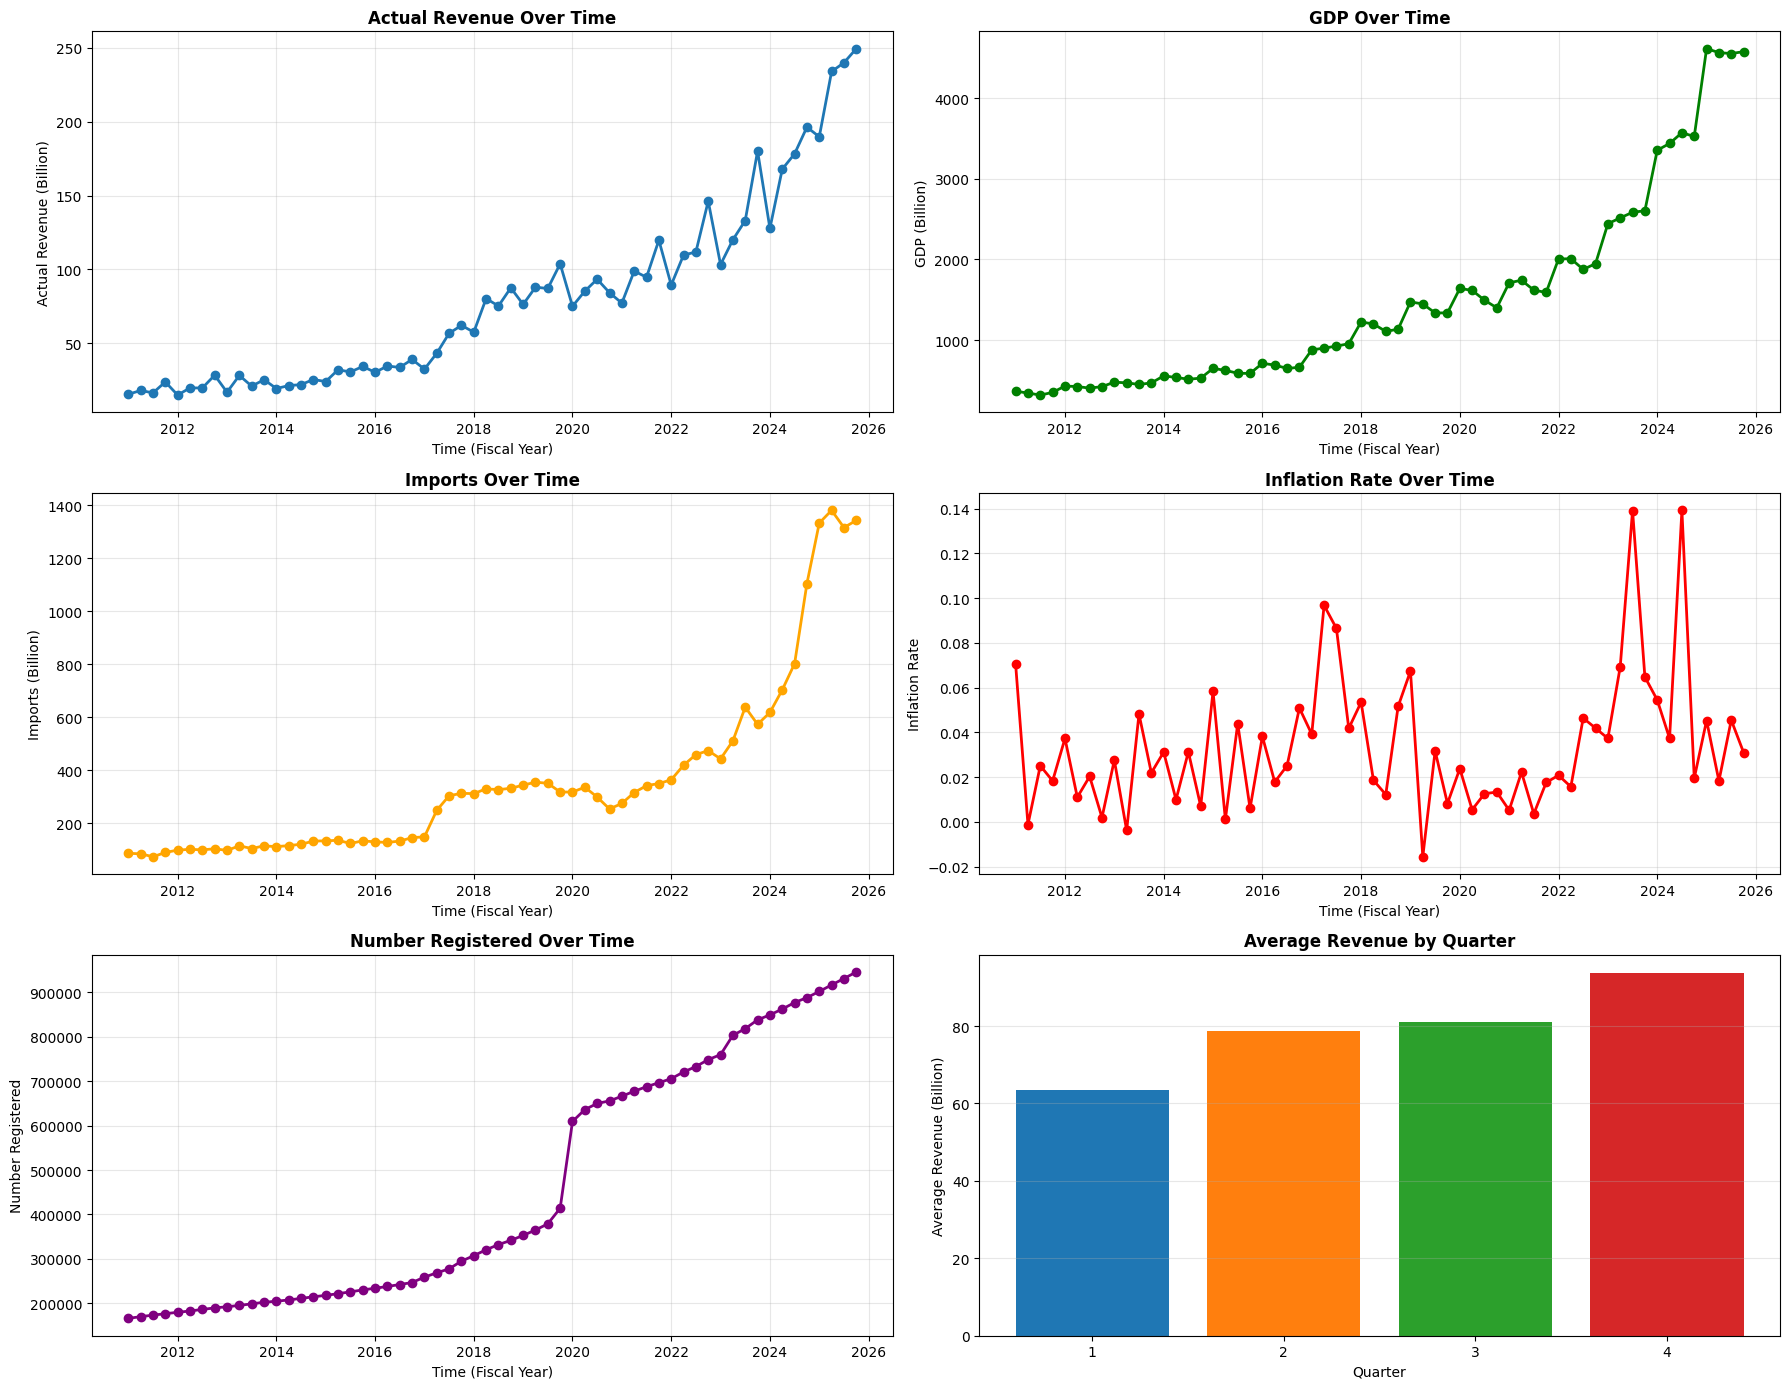

In [24]:
print("TIME SERIES ANALYSIS")

# Create time index
df['Time_Index'] = df['Fiscal_Year'] + (df['Quarter'] - 1) / 4

fig, axes = plt.subplots(3, 2, figsize=(18, 14))

# Plot 1: Actual Revenue over time
axes[0, 0].plot(df['Time_Index'], df['Actual_Revenue'], marker='o', linewidth=2)
axes[0, 0].set_title('Actual Revenue Over Time', fontweight='bold')
axes[0, 0].set_xlabel('Time (Fiscal Year)')
axes[0, 0].set_ylabel('Actual Revenue (Billion)')
axes[0, 0].grid(alpha=0.3)

# Plot 2: GDP over time
axes[0, 1].plot(df['Time_Index'], df['GDP_Market_Price'], marker='o', linewidth=2, color='green')
axes[0, 1].set_title('GDP Over Time', fontweight='bold')
axes[0, 1].set_xlabel('Time (Fiscal Year)')
axes[0, 1].set_ylabel('GDP (Billion)')
axes[0, 1].grid(alpha=0.3)

# Plot 3: Imports over time
axes[1, 0].plot(df['Time_Index'], df['Imports'], marker='o', linewidth=2, color='orange')
axes[1, 0].set_title('Imports Over Time', fontweight='bold')
axes[1, 0].set_xlabel('Time (Fiscal Year)')
axes[1, 0].set_ylabel('Imports (Billion)')
axes[1, 0].grid(alpha=0.3)

# Plot 4: Inflation Rate over time
axes[1, 1].plot(df['Time_Index'], df['Inflation_Rate'], marker='o', linewidth=2, color='red')
axes[1, 1].set_title('Inflation Rate Over Time', fontweight='bold')
axes[1, 1].set_xlabel('Time (Fiscal Year)')
axes[1, 1].set_ylabel('Inflation Rate')
axes[1, 1].grid(alpha=0.3)

# Plot 5: Number Registered over time
axes[2, 0].plot(df['Time_Index'], df['Number_Registered'], marker='o', linewidth=2, color='purple')
axes[2, 0].set_title('Number Registered Over Time', fontweight='bold')
axes[2, 0].set_xlabel('Time (Fiscal Year)')
axes[2, 0].set_ylabel('Number Registered')
axes[2, 0].grid(alpha=0.3)

# Plot 6: Quarterly patterns
quarterly_avg = df.groupby('Quarter')['Actual_Revenue'].mean()
axes[2, 1].bar(quarterly_avg.index, quarterly_avg.values, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
axes[2, 1].set_title('Average Revenue by Quarter', fontweight='bold')
axes[2, 1].set_xlabel('Quarter')
axes[2, 1].set_ylabel('Average Revenue (Billion)')
axes[2, 1].set_xticks([1, 2, 3, 4])
axes[2, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
y = df['Actual_Revenue']
X = df[['Quarter', 'Fiscal_Year', 'GDP_Market_Price', 'Imports', 'Inflation_Rate', 'Number_Registered']]
X_original_full = X.copy()
print("Target variable 'y' and feature set 'X' (and its copy 'X_original_full') have been created.")

Target variable 'y' and feature set 'X' (and its copy 'X_original_full') have been created.


In [26]:
from sklearn.model_selection import train_test_split

# test_size = 0.2 means 20% of the data for testing
# shuffle=False is crucial for time-series splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Time-aware train-test split completed.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

Time-aware train-test split completed.
X_train shape: (48, 6)
X_test shape: (12, 6)
y_train shape: (48,)
y_test shape: (12,)


# **Model**

In [126]:
models_and_params = {
    'Ridge': {
        'model': Ridge(random_state=42),
        'params': {
            'alpha': [0.001, 0.01, 0.1, 1, 10, 100]
        }
    },

    'Lasso': {
        'model': Lasso(random_state=42, max_iter=10000),
        'params': {
            'alpha': [0.001, 0.01, 0.1, 1, 10]
        }
    },

    'ElasticNet': {
        'model': ElasticNet(random_state=42, max_iter=10000),
        'params': {
            'alpha': [0.01, 0.1, 1, 10],
            'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
        }
    },

    # ========== K-NEAREST NEIGHBORS ==========
    'KNN': {
        'model': KNeighborsRegressor(),
        'params': {
            'n_neighbors': [3, 5, 7, 9, 11, 15],
            'weights': ['uniform', 'distance'],
            'metric': ['euclidean', 'manhattan', 'minkowski'],
            'p': [1, 2]
        }
    }
}

In [127]:
results = []

for model_name, config in models_and_params.items():
    print(f"\n{'='*80}")
    print(f"Training: {model_name}")
    print(f"{'='*80}")

    model = config['model']
    params = config['params']

    # ===============================
    # 1. Hyperparameter Tuning
    # ===============================
    if params:   # Model has hyperparameters → use GridSearchCV
        grid_search = GridSearchCV(
            estimator=model,
            param_grid=params,
            cv=cv_strategy,
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            verbose=1
        )

        grid_search.fit(X_train_orig_scaled, y_train)
        best_model = grid_search.best_estimator_

        print(f"\nBest Parameters: {grid_search.best_params_}")
        print(f"Best CV Score (MSE): {-grid_search.best_score_:.4f}")

    else:        # Models like LinearRegression (no params)
        best_model = model
        best_model.fit(X_train_orig_scaled, y_train)

    # ===============================
    # 2. Cross-validation (FULL DATA)
    # ===============================
    cv_r2 = cross_val_score(best_model, X_orig_scaled_full, y,
                             cv=cv_strategy, scoring='r2')

    cv_mse = -cross_val_score(best_model, X_orig_scaled_full, y,
                               cv=cv_strategy, scoring='neg_mean_squared_error')

    cv_mae = -cross_val_score(best_model, X_orig_scaled_full, y,
                               cv=cv_strategy, scoring='neg_mean_absolute_error')

    # ===============================
    # 3. Train Test Evaluation
    # ===============================
    best_model.fit(X_train_orig_scaled, y_train)

    y_pred_train = best_model.predict(X_train_orig_scaled)
    y_pred_test = best_model.predict(X_test_orig_scaled)

    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)

    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)

    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)

    # ===============================
    # 4. Store Results
    # ===============================
    results.append({
        'Model': model_name,
        'CV_R2_Mean': cv_r2.mean(),
        'CV_R2_Std': cv_r2.std(),
        'CV_MSE_Mean': cv_mse.mean(),
        'CV_MAE_Mean': cv_mae.mean(),
        'Train_R2': train_r2,
        'Test_R2': test_r2,
        'Train_MSE': train_mse,
        'Test_MSE': test_mse,
        'Train_MAE': train_mae,
        'Test_MAE': test_mae,
        'Overfitting_Gap': train_r2 - test_r2
    })

    # ===============================
    # 5. Print Summary
    # ===============================
    print(f"\n--- Results for {model_name} ---")
    print(f"CV R² (mean ± std): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
    print(f"CV MSE (mean): {cv_mse.mean():.4f}")
    print(f"CV MAE (mean): {cv_mae.mean():.4f}")
    print(f"Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"Train MSE: {train_mse:.4f} | Test MSE: {test_mse:.4f}")
    print(f"Overfitting Gap: {train_r2 - test_r2:.4f}")


Training: Ridge
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best Parameters: {'alpha': 1}
Best CV Score (MSE): 195.4401

--- Results for Ridge ---
CV R² (mean ± std): -0.7238 ± 1.5657
CV MSE (mean): 270.3182
CV MAE (mean): 12.2196
Train R²: 0.9650 | Test R²: -0.1225
Train MSE: 42.4270 | Test MSE: 2438.1519
Overfitting Gap: 1.0875

Training: Lasso
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best Parameters: {'alpha': 0.1}
Best CV Score (MSE): 250.8131

--- Results for Lasso ---
CV R² (mean ± std): -0.6674 ± 1.3075
CV MSE (mean): 567.3934
CV MAE (mean): 16.3444
Train R²: 0.9655 | Test R²: -0.6166
Train MSE: 41.8054 | Test MSE: 3511.2714
Overfitting Gap: 1.5821

Training: ElasticNet
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best Parameters: {'alpha': 0.01, 'l1_ratio': 0.1}
Best CV Score (MSE): 174.4074

--- Results for ElasticNet ---
CV R² (mean ± std): -0.0714 ± 0.7911
CV MSE (mean): 286.7883
CV MAE (mean): 12.2489
Train R²: 0.9654 

In [118]:
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import GridSearchCV, cross_val_score
import numpy as np

model_name = "Simple MLP Regressor"

In [119]:
mlp = MLPRegressor(max_iter=2000, random_state=42)

params = {
    "hidden_layer_sizes": [(16,), (32,), (16,16)],
    "activation": ["relu"],
    "alpha": [0.0001, 0.001, 0.01],
    "solver": ["adam"]
}

In [120]:
# ===== Grid Search =====
grid_search = GridSearchCV(
    estimator=mlp,
    param_grid=params,
    cv=cv_strategy,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=0
)

In [121]:
grid_search.fit(X_train_orig_scaled, y_train)
best_model = grid_search.best_estimator_

print(f"Best Parameters: {grid_search.best_params_}")

Best Parameters: {'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (32,), 'solver': 'adam'}


In [122]:
# ===== Predictions =====
y_pred_train = best_model.predict(X_train_orig_scaled)
y_pred_test = best_model.predict(X_test_orig_scaled)

# ===== Metrics =====
train_r2 = r2_score(y_train, y_pred_train)
test_r2 = r2_score(y_test, y_pred_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

train_mae = mean_absolute_error(y_train, y_pred_train)
test_mae = mean_absolute_error(y_test, y_pred_test)

train_mape = mean_absolute_percentage_error(y_train, y_pred_train) * 100
test_mape = mean_absolute_percentage_error(y_test, y_pred_test) * 100

In [124]:
# ===== CV on full dataset =====
cv_r2 = cross_val_score(best_model, X_orig_scaled_full, y,
                        cv=cv_strategy, scoring='r2')

cv_mse = -cross_val_score(best_model, X_orig_scaled_full, y,
                          cv=cv_strategy, scoring='neg_mean_squared_error')

# ===== OUTPUT =====
print(f"\n--- Results ---")
print(f"Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
print(f"Train RMSE: {train_rmse:.4f} | Test RMSE: {test_rmse:.4f}")
print(f"Train MAE: {train_mae:.4f} | Test MAE: {test_mae:.4f}")
print(f"Train MAPE: {train_mape:.2f}% | Test MAPE: {test_mape:.2f}%")
print(f"CV R² (mean ± std): {cv_r2.mean():.4f} ± {cv_r2.std():.4f}")
print(f"Overfitting Gap: {train_r2 - test_r2:.4f}")


--- Results ---
Train R²: 0.9689 | Test R²: -3.2168
Train RMSE: 6.1459 | Test RMSE: 95.7041
Train MAE: 4.7951 | Test MAE: 80.2552
Train MAPE: 10.84% | Test MAPE: 42.64%
CV R² (mean ± std): -5.9025 ± 8.9120
Overfitting Gap: 4.1857


In [113]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

models_config = {

    '1. Linear Regression': {
        'model': LinearRegression(),
        'params': {
            # Linear regression has no hyperparameters — dummy to allow GridSearch
            'fit_intercept': [True, False]
        }
    },

    '2. Ridge Regression': {
        'model': Ridge(random_state=42),
        'params': {
            'alpha': [0.01, 0.1, 1, 10, 50, 100]
        }
    },

    '3. Lasso Regression': {
        'model': Lasso(random_state=42, max_iter=10000),
        'params': {
            'alpha': [0.001, 0.01, 0.1, 1, 10]
        }
    },

    '4. ElasticNet': {
        'model': ElasticNet(random_state=42, max_iter=10000),
        'params': {
            'alpha': [0.01, 0.1, 1, 10],
            'l1_ratio': [0.2, 0.5, 0.8]
        }
    },

    '5. Support Vector Regression (Linear)': {
        'model': SVR(kernel="linear"),
        'params': {
            'C': [0.1, 1, 10, 50, 100],
            'epsilon': [0.01, 0.1, 0.5]
        }
    },

    '6. MLP Regressor (Simple NN)': {
        'model': MLPRegressor(random_state=42, max_iter=5000),
        'params': {
            'hidden_layer_sizes': [(16,), (32,), (16, 8)],
            'learning_rate_init': [0.001, 0.01],
            'alpha': [0.0001, 0.001, 0.01]
        }
    },
}


In [114]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

cv_strategy = TimeSeriesSplit(n_splits=5)

In [ ]:
loocv = LeaveOneOut()
# 5-fold or 10-fold CV (faster but less data per iteration)
from sklearn.model_selection import KFold
kfold_5 = KFold(n_splits=5, shuffle=True, random_state=42)
kfold_10 = KFold(n_splits=10, shuffle=True, random_state=42)

# LOOCV for best results, KFold for speed)
cv_strategy = loocv

In [ ]:
results = []

for model_name, config in models_and_params.items():
    print(f"\n{'='*80}")
    print(f"Training: {model_name}")
    print(f"{'='*80}")

    model = config['model']
    params = config['params']

    if params:  # If hyperparameters exist, use GridSearchCV
        grid_search = GridSearchCV(
            estimator=model,
            param_grid=params,
            cv=cv_strategy,
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            verbose=1
        )

        grid_search.fit(X_scaled, y)
        best_model = grid_search.best_estimator_

        print(f"\nBest Parameters: {grid_search.best_params_}")
        print(f"Best CV Score (MSE): {-grid_search.best_score_:.4f}")

    else:  # No hyperparameters (e.g., Linear Regression)
        best_model = model
        best_model.fit(X_train, y_train)

    # Cross-validation on entire dataset
    cv_scores = cross_val_score(best_model, X_scaled, y,
                                 cv=cv_strategy,
                                 scoring='r2')
    cv_mse = -cross_val_score(best_model, X_scaled, y,
                               cv=cv_strategy,
                               scoring='neg_mean_squared_error')
    cv_mae = -cross_val_score(best_model, X_scaled, y,
                               cv=cv_strategy,
                               scoring='neg_mean_absolute_error')

    # Train on full training set and evaluate on test set
    best_model.fit(X_train, y_train)
    y_pred_train = best_model.predict(X_train)
    y_pred_test = best_model.predict(X_test)

    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    train_mse = mean_squared_error(y_train, y_pred_train)
    test_mse = mean_squared_error(y_test, y_pred_test)
    train_mae = mean_absolute_error(y_train, y_pred_train)
    test_mae = mean_absolute_error(y_test, y_pred_test)

    # Store results
    results.append({
        'Model': model_name,
        'CV_R2_Mean': cv_scores.mean(),
        'CV_R2_Std': cv_scores.std(),
        'CV_MSE_Mean': cv_mse.mean(),
        'CV_MAE_Mean': cv_mae.mean(),
        'Train_R2': train_r2,
        'Test_R2': test_r2,
        'Train_MSE': train_mse,
        'Test_MSE': test_mse,
        'Train_MAE': train_mae,
        'Test_MAE': test_mae,
        'Overfitting_Gap': train_r2 - test_r2
    })

    print(f"\n--- Results for {model_name} ---")
    print(f"CV R² (mean ± std): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"CV MSE (mean): {cv_mse.mean():.4f}")
    print(f"CV MAE (mean): {cv_mae.mean():.4f}")
    print(f"Train R²: {train_r2:.4f} | Test R²: {test_r2:.4f}")
    print(f"Train MSE: {train_mse:.4f} | Test MSE: {test_mse:.4f}")
    print(f"Overfitting Gap (Train R² - Test R²): {train_r2 - test_r2:.4f}")


Training: Linear Regression

--- Results for Linear Regression ---
CV R² (mean ± std): nan ± nan
CV MSE (mean): 201.5287
CV MAE (mean): 10.2077
Train R²: 0.9549 | Test R²: 0.9601
Train MSE: 161.9928 | Test MSE: 171.9118
Overfitting Gap (Train R² - Test R²): -0.0052

Training: Ridge
Fitting 60 folds for each of 7 candidates, totalling 420 fits

Best Parameters: {'alpha': 0.1}
Best CV Score (MSE): 199.9744

--- Results for Ridge ---
CV R² (mean ± std): nan ± nan
CV MSE (mean): 199.9744
CV MAE (mean): 10.1245
Train R²: 0.9546 | Test R²: 0.9635
Train MSE: 162.9017 | Test MSE: 157.0199
Overfitting Gap (Train R² - Test R²): -0.0089

Training: Lasso
Fitting 60 folds for each of 6 candidates, totalling 360 fits

Best Parameters: {'alpha': 1}
Best CV Score (MSE): 190.3088

--- Results for Lasso ---
CV R² (mean ± std): nan ± nan
CV MSE (mean): 190.3088
CV MAE (mean): 9.8219
Train R²: 0.9514 | Test R²: 0.9720
Train MSE: 174.3478 | Test MSE: 120.5166
Overfitting Gap (Train R² - Test R²): -0.0206
